In [1]:
from qc_grader.challenges.fallfest_2026.bell import (
    grade_bell_ex1, grade_bell_ex2, grade_bell_ex3, grade_bell_ex4,
    grade_bell_ex5, grade_bell_ex6, grade_bell_ex7, grade_bell_ex8,
    grade_bell_ex9, grade_bell_ex10, grade_bell_ex11, grade_bell_ex12,
    grade_bell_ex13, grade_bell_ex14, grade_bell_ex15, grade_bell_ex16,
    grade_bell_ex17, grade_bell_ex18,
)

from qc_grader.challenges.fallfest_2026 import check_progress

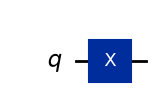

In [2]:
from qiskit import QuantumCircuit

qc = QuantumCircuit(1)
qc.x(0)
qc.draw("mpl")

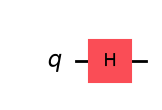

In [3]:
qc = QuantumCircuit(1)
qc.h(0)
qc.draw("mpl")

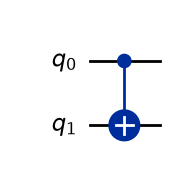

In [4]:
qc = QuantumCircuit(2)
qc.cx(0, 1)
qc.draw("mpl")

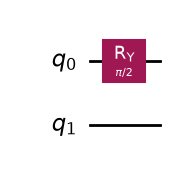

In [5]:
import numpy as np

pi = np.pi

qc = QuantumCircuit(2)
qc.ry(pi / 2, 0)
qc.draw("mpl")

In [20]:
# We'll begin by importing qiskit and a visualization module so that we can plot a
# histogram of our results.

from qiskit.visualization import plot_histogram

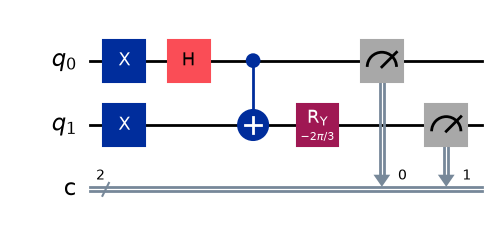

In [21]:
# We start by declaring our first quantum circuit, and giving it two qubits (the first "2") and two
# classical bits for storing outputs (the second "2")
# Define registers
from qiskit import ClassicalRegister, QuantumRegister

qr = QuantumRegister(2, "q")
cr = ClassicalRegister(2, "c")
qc1 = QuantumCircuit(qr, cr)

# We know from our analysis above that we need an X gate acting on each of the qubits (L and R)
qc1.x([0, 1])
# We need a Hadamard gate acting on Lucas's qubit, which we're calling the 0th qubit.
qc1.h(0)
# The controlled-NOT gate uses the 0th qubit (Lucas's) as the control and the 1st qubit (Rihanna's)
# as the target.
qc1.cx(0, 1)
# The rotation gate acts on the 1st qubit (Rihanna's) and has an argument of -2 pi/3
qc1.ry(-2 * pi / 3, 1)
# Finally, we want to measure all the qubits in the circuit to obtain measurement probabilities, and
# store the results in the classical bits.
qc1.measure([0, 1], [0, 1])
# Now we can draw the first of the three circuits that will check Bell's inequality for us.
qc1.draw(output="mpl")

In [22]:
qcs = [QuantumCircuit(2, 2), QuantumCircuit(2, 2), QuantumCircuit(2, 2)]
for i in range(0, len(qcs)):
    qcs[i].x([0, 1])
    qcs[i].h(0)
    qcs[i].cx(0, 1)

qcs[0].ry(-2 * pi / 3, 1)
qcs[1].ry(-4 * pi / 3, 1)
qcs[2].ry(-2 * pi / 3, 1)
qcs[2].ry(-4 * pi / 3, 1)

for i in range(0, len(qcs)):
    qcs[i].barrier()
    qcs[i].measure([0, 1], [0, 1])

counts_list = [None] * len(qcs)

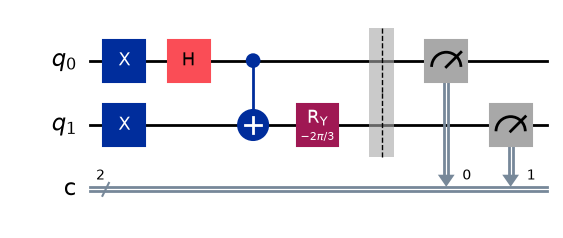

In [23]:
qcs[0].draw(output="mpl")

In [24]:
from qiskit.primitives import StatevectorSampler

sampler = StatevectorSampler()

# Start a job that will return shots for all 100 parameter value sets.
for i in range(0, len(qcs)):
    pub = qcs[i]
    job = sampler.run([pub], shots=10000)
    # Extract the result for the 0th pub (this example only has one pub).
    result = job.result()
    data_pub = result[0].data
    counts = data_pub.c.get_counts()
    counts_list[i] = counts
#    plot_histogram(counts)

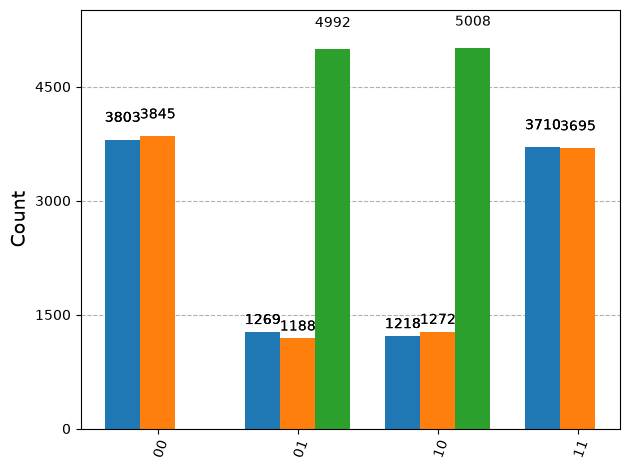

In [25]:
plot_histogram(counts_list)

In [26]:
outcomes = ("00", "01", "10", "11")

# Here we convert "None"s into 0's so that we can sum.

for i in range(0, len(qcs)):
    for j in range(0, len(outcomes)):
        if counts_list[i].get(outcomes[j]) is None:
            counts_list[i].update({outcomes[j]: 0})

# Here we create a dictionary that holds all the outcomes and sums over their appearances
# in each of the circuits.

total_counts = {}
for i in range(0, len(outcomes)):
    total_counts[outcomes[i]] = sum(
        counts_list[j].get(outcomes[i]) for j in range(0, len(qcs))
    )

{'00': 7648, '01': 7449, '10': 7498, '11': 7405}


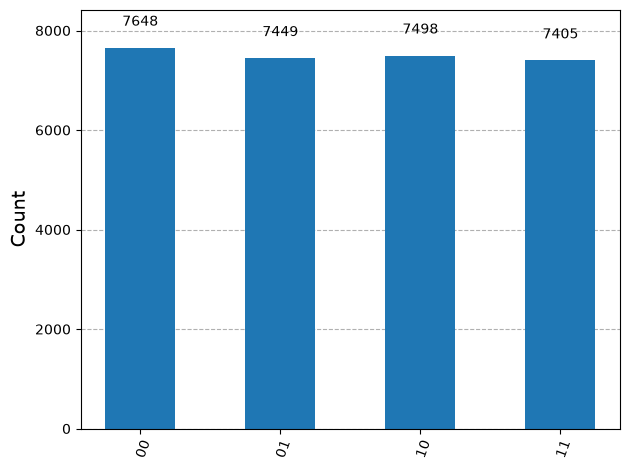

In [27]:
print(total_counts)
plot_histogram(total_counts)

In [28]:
from qiskit_ibm_runtime import QiskitRuntimeService

# Syntax for first saving your token. Delete these lines after saving your credentials.
# QiskitRuntimeService.save_account(channel='ibm_quantum_platform',
# instance = '<YOUR_IBM_INSTANCE_CRN>', token='<YOUR-API_KEY>', overwrite=True, set_as_default=True)
# service = QiskitRuntimeService(channel='ibm_quantum_platform')

# Load saved credentials
service = QiskitRuntimeService()

backend = service.least_busy(operational=True)

In [29]:
from qiskit.transpiler.preset_passmanagers import generate_preset_pass_manager

target = backend.target
pm = generate_preset_pass_manager(target=target, optimization_level=3)

qcs_isa = qcs

for i in range(0, len(qcs)):
    qcs_isa[i] = pm.run(qcs[i])
    qcs_isa[i].draw(output="mpl", idle_wires=False, style="iqp")

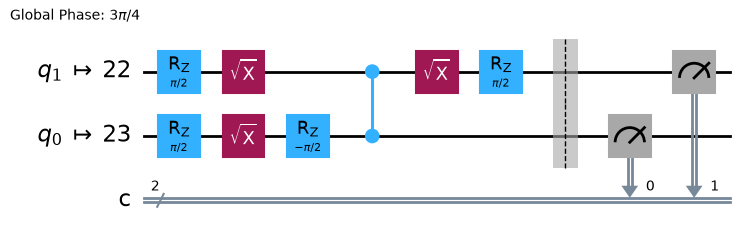

In [30]:
qcs_isa[2].draw(output="mpl", idle_wires=False, style="iqp")

In [31]:
from qiskit_ibm_runtime import SamplerV2 as Sampler
# from qiskit_ibm_runtime import Session
# sampler.options.default_shots = 1000

# Start a job that will return shots for all 100 parameter value sets.
# The best practice is to use a session as shown below. This is available to Premium Plan, Flex
# Plan, and On-Prem (IBM Quantum Platform API) Plan users.
# result_list = [None] * len(qcs)
# real_counts_list = [None] * len(qcs)
# with Session(backend=backend) as session:
#    sampler = Sampler(mode=session)

#    for i in range(0, len(qcs)):
#        # Define the primitive unified bloc (pub)
#        pub = qcs[i]
#        job = sampler.run([pub], shots=10000)
#        # Extract the result for the 0th pub (this example only has one pub).
#        result_list[i] = job.result()
#        data_pub = result_list[i][0].data
#        counts = data_pub.c.get_counts()
#        real_counts_list[i] = counts
#    #   plot_histogram(counts)

# Open users can still carry out this experiment, but without reserving a session of use, meaning
# repeated queuing is possible.
from qiskit_ibm_runtime import Batch

batch = Batch(backend=backend)
sampler = Sampler(mode=batch)

result_list = [None] * len(qcs)
real_counts_list = [None] * len(qcs)

for i in range(0, len(qcs)):
    # Define the primitive unified bloc (pub)
    pub = qcs[i]
    job = sampler.run([pub], shots=10000)
    # Extract the result for the 0th pub (this example only has one pub).
    result_list[i] = job.result()
    data_pub = result_list[i][0].data
    counts = data_pub.c.get_counts()
    real_counts_list[i] = counts

# Close the batch because no context manager was used.
batch.close()

{'00': 7649, '01': 7308, '10': 7705, '11': 7338}


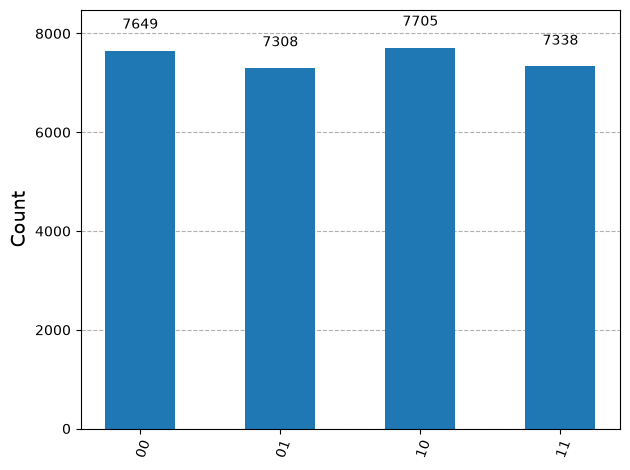

In [32]:
outcomes = ("00", "01", "10", "11")

# Here we convert "None"s into 0's so that we can sum.

for i in range(0, len(qcs)):
    for j in range(0, len(outcomes)):
        if real_counts_list[i].get(outcomes[j]) is None:
            real_counts_list[i].update({outcomes[j]: 0})

# Here we create a dictionary that holds all the outcomes and sums over their appearances
# in each of the circuits.

real_total_counts = {}
for i in range(0, len(outcomes)):
    real_total_counts[outcomes[i]] = sum(
        real_counts_list[j].get(outcomes[i]) for j in range(0, len(qcs))
    )

print(real_total_counts)
plot_histogram(real_total_counts)

In [34]:
# This syntax allows you to run the job on a simulator, in case you have exhausted your allotted
# time on real IBM quantum computers.
# But we strongly advise running this on real quantum computers, since this is meant to be a check
# of the behavior of real quantum systems.

# This uses a local simulator
# from qiskit_aer import AerSimulator

# This generates a simulator that mimics the real quantum system
# backend_sim = AerSimulator.from_backend(backend)

# Import an estimator, this time from qiskit (we import from Runtime for real hardware)
# from qiskit.primitives import BackendSamplerV2
# sampler = BackendSamplerV2(backend = backend_sim)

# result_list = [None] * len(qcs)
# counts_list = [None] * len(qcs)
# for i in range(0, len(qcs)):
# Define the primitive unified bloc (pub)
#    pub = qcs[i]
#    job = sampler.run([pub], shots=10000)
# Extract the result for the 0th pub (this example only has one pub).
#    result_list[i] = job.result()
#    data_pub = result_list[i][0].data
#    counts = data_pub.c.get_counts()
#    counts_list[i] = counts

# data_pubs = (result_list[0][0].data,result_list[1][0].data,result_list[2][0].data)
# outcomes = ("00", "01", "10", "11")

# Here we convert "None"s into 0's so that we can sum.

# for i in range(0, len(qcs)):
#    for j in range(0, len(outcomes)):
#        if counts_list[i].get(outcomes[j]) is None:
#            counts_list[i].update({outcomes[j]: 0})

# Here we create a dictionary that holds all the outcomes and sums over their appearances
# in each of the circuits.

# total_counts = {}
# for i in range(0, len(outcomes)):
#    total_counts[outcomes[i]] = sum(
#        counts_list[j].get(outcomes[i]) for j in range(0, len(qcs))
#    )

# print(total_counts)
# plot_histogram(total_counts)

In [35]:
counts_list

[{'00': 3803, '10': 1218, '11': 3710, '01': 1269},
 {'01': 1188, '11': 3695, '10': 1272, '00': 3845},
 {'10': 5008, '01': 4992, '00': 0, '11': 0}]

In [36]:
answer = True  # Replace with True or False
grade_bell_ex1(answer)

Grading your answer. Please wait...

Correct! Einstein held QM incomplete because it gives only probabilities, not the mechanism fixing each outcome.
You scored 1 on this exercise.


In [37]:
answer = False  # Replace with True or False
grade_bell_ex2(answer)

Grading your answer. Please wait...

Correct! 'Hidden variables' means pre-existing definite values, not entanglement.
You scored 1 on this exercise.


In [38]:
answer = False  # Replace with True or False
grade_bell_ex3(answer)

Grading your answer. Please wait...

Correct! Classical correlation is not entanglement.
You scored 1 on this exercise.


In [39]:
answer = False  # Replace with True or False
grade_bell_ex4(answer)

Grading your answer. Please wait...

Correct! Entanglement is observable via Bell inequality violations.
You scored 1 on this exercise.


In [40]:
answer = True # Replace with True or False
grade_bell_ex5(answer)

Grading your answer. Please wait...

Correct! In general QM predicts only probabilities, not exact outcomes.
You scored 1 on this exercise.


In [41]:
answer = True  # Replace with True or False
grade_bell_ex6(answer)

Grading your answer. Please wait...

Correct! Measuring entangled partner B fixes the state of distant particle A.
You scored 1 on this exercise.


In [42]:
answer = True  # Replace with True or False
grade_bell_ex7(answer)

Grading your answer. Please wait...

Correct! Real Bell experiments map directly onto quantum circuits.
You scored 1 on this exercise.


In [43]:
answer = "a"  # Replace with your answer: "a", "b", "c", or "d"
grade_bell_ex8(answer)

Grading your answer. Please wait...

Correct! A measured along +z forces B to -z.
You scored 1 on this exercise.


In [49]:
answer = ["f"]  # Replace with a list of your answers, e.g. ["a", "b", "c"]
grade_bell_ex9(answer)

Grading your answer. Please wait...


Not quite! Revisit what outcomes a |-z> partner gives along z, x, or y in the "What does Born's option (non-deterministic quantum mechanics) predict?" section of the notebook. You're missing one or more correct answers.
Please review your answer and try again.


In [52]:
answer = "c"  # Replace with your answer: "a", "b", "c", "d", or "e"
grade_bell_ex10(answer)

Grading your answer. Please wait...


Not quite! Revisit the spin being undetermined by nature before measurement in the "What does Born's option (non-deterministic quantum mechanics) predict?" section of the notebook.
Please review your answer and try again.


In [53]:
answer = ["a", "c","d"]  # Replace with a list of your answers, e.g. ["a", "d"]
grade_bell_ex11(answer)

Grading your answer. Please wait...


Not quite! Revisit how the Hadamard gate acts on |0> and on |+>/|-> in the "From physical experiment to quantum circuits" section of the notebook. Some of your selections are incorrect.
Please review your answer and try again.


In [54]:
answer = ["a", "d","e"]  # Replace with a list of your answers, e.g. ["a", "c"]
grade_bell_ex12(answer)

Grading your answer. Please wait...


Not quite! Revisit how the X gate acts on |0> and |1> in the "From physical experiment to quantum circuits" section of the notebook. Some of your selections are incorrect.
Please review your answer and try again.


In [55]:
answer = "a"  # Replace with your answer: "a", "b", "c", or "d"
grade_bell_ex13(answer)

Grading your answer. Please wait...


Not quite! Revisit which gates are single- vs two-qubit (CNOT) in the "From physical experiment to quantum circuits" section of the notebook.
Please review your answer and try again.


In [56]:
answer = "b"  # Replace with your answer: "a", "b", "c", or "d"
grade_bell_ex14(answer)

Grading your answer. Please wait...


Not quite! Revisit ideal vs real-hardware outcome probabilities for |0> in the "Test using real quantum computers!" section of the notebook.
Please review your answer and try again.


In [57]:
answer = """I agree with Friend B. Bell's inequality experiments show that quantum particles cannot be explained by local hidden variables with predetermined measurement outcomes. The results do not mean that particles simply lack knowledge of their spin states."""
grade_bell_ex15(answer)

Grading your answer. Please wait...

Friend C. The Bell violation rules out pre-existing hidden instructions, so the outcome was undetermined by nature, not merely unknown. Friend A (only unknown) and Friend B (no definite direction) are both still compatible with hidden variables, which the experiment excludes.
You scored 1 on this exercise.


In [58]:
answer = """Entangled particles show correlations stronger than any theory based on local hidden variables can explain, even when measured far apart. These correlations suggest that quantum reality cannot be explained by local hidden variables, although they cannot be used to send information faster than light."""
grade_bell_ex16(answer)

Grading your answer. Please wait...

Measuring one entangled particle along +z fixes the distant partner at -z, even though neither spin had a definite value beforehand. A property of one particle thus depends on what is done to a far-away particle, which no local hidden-variable theory can reproduce; this dependence is non-locality.
You scored 1 on this exercise.


In [59]:
answer = """I would repeat the experiment many times with different measurement angles and a larger number of entangled particle pairs. I would also reduce experimental errors and compare the results with Bell's inequality predictions."""
grade_bell_ex17(answer)

Grading your answer. Please wait...

Open: e.g. check measurement timing via coincidence counting, vary the relative angles between axes, or run the test with entangled photons.
You scored 1 on this exercise.


In [60]:
answer = """Yes, Bell's inequality can be explored using different numbers and arrangements of measurement axes. Three equally spaced axes are one possible choice, but other measurement angles can also be used to test quantum correlations. The choice of angles affects the observed violation."""
grade_bell_ex18(answer)

Grading your answer. Please wait...

No. Other numbers of axes work as long as the directions stay distinct. Five equally-spaced directions work, since none is the negative of another. Four equally-spaced directions fail because opposite directions coincide (e.g. +a lines up with -c), losing a setting.
You scored 1 on this exercise.


In [61]:
check_progress("bell")

Fetching your progress. Please wait...

📊 Your progress

Lab "bell" — 12/18 passed, score 12.0
  ✅ ex1 — score 1.0
  ✅ ex2 — score 1.0
  ✅ ex3 — score 1.0
  ✅ ex4 — score 1.0
  ✅ ex5 — score 1.0
  ✅ ex6 — score 1.0
  ✅ ex7 — score 1.0
  ✅ ex8 — score 1.0
  ⬜ ex9 — score 0.0
  ⬜ ex10 — score 0.0
  ⬜ ex11 — score 0.0
  ⬜ ex12 — score 0.0
  ⬜ ex13 — score 0.0
  ⬜ ex14 — score 0.0
  ✅ ex15 — score 1.0
  ✅ ex16 — score 1.0
  ✅ ex17 — score 1.0
  ✅ ex18 — score 1.0
